In [1]:
# Add relevant Jupyter notebook extensions 

In [1]:
# You can double-check your Python path like this...
import sys  
print(sys.path)

['c:\\Users\\ldots\\anaconda3\\python313.zip', 'c:\\Users\\ldots\\anaconda3\\DLLs', 'c:\\Users\\ldots\\anaconda3\\Lib', 'c:\\Users\\ldots\\anaconda3', '', 'c:\\Users\\ldots\\anaconda3\\Lib\\site-packages', 'c:\\Users\\ldots\\anaconda3\\Lib\\site-packages\\win32', 'c:\\Users\\ldots\\anaconda3\\Lib\\site-packages\\win32\\lib', 'c:\\Users\\ldots\\anaconda3\\Lib\\site-packages\\Pythonwin']


# LS' Initial Solo Controller Test

In [6]:
# Import Python's sys module: grants access to modify where Python searches for modules
import sys

# Import Path, to work with folders and file paths
# Get current working directory (cwd) and parent directory (one level up the folder hierarchy)
# "When looking for modules, also search the parent folder first."
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

# Import the PDController class from the uuv_mission.control module
from uuv_mission.control import PDController
controller = PDController()

# Test the controller with some example inputs controller(10, 0)  # Example input: reference=10, observation=0
# We expect the output to be 7.5 based on the PD control law with the given parameters (kp=0.15, kd=0.6)
assert abs(controller(10, 0) - 7.5) < 1e-10
assert abs(controller(10, 2) - 0.0) < 1e-10

# Check correct reset of the controller's internal state before running the next test
controller.reset()

# Test the controller with another set of inputs
assert abs(controller(10, 8) - 1.5) < 1e-10

print("All controller tests passed!")

All controller tests passed!


# Simulate closed-loop
After implementing your control functionality, you can simulate the closed-loop with code that looks something like this...

c:\Users\ldots\Documents\Desk\Study Drive\Vault\Academics\University Studies\Year 3\B1 Engineering Computation\b101_scientific_coding\Local_repo_clone\b1-coding-practical-mt24\notebooks
<class 'uuv_mission.LS_dynamic.Mission'>


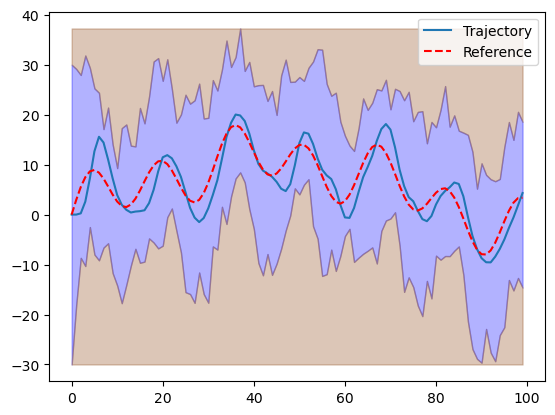

In [5]:
import sys
import numpy as np

import os
print(os.getcwd())

from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

# Import relevant modules
from uuv_mission.LS_dynamic import Submarine, ClosedLoop, Mission, Trajectory
from uuv_mission.control import PDController

# Instantiate controller & submarine (depending on your implementation)
sub = Submarine()
controller = PDController(Kp=0.15, Kd=0.6)  # Example parameters, adjust as needed

# Assemble the closed-loop system
closed_loop = ClosedLoop(sub, controller)

# Load the mission reference and boundaries from csv file
mission = Mission.from_csv("../data/mission.csv") # You must implement this method in the Mission class
print(type(mission))

# Simulate the closed-loop system with random disturbances
np.random.seed(42)  # For reproducibility
trajectory = closed_loop.simulate_with_random_disturbances(mission)

# Plot the completed mission trajectory
trajectory.plot_completed_mission(mission)